# Chapitre 12 - Cours 3 : observer l'état dérivé

Les cours 1 et 2 ont décrit comment les données dérivées sont **produites** et tenues à
jour. Ce notebook regarde l'autre bout : comment elles sont **lues**. Il couvre la
section *Observing Derived State* : la frontière entre chemin d'écriture et chemin de
lecture, les caches et vues matérialisées, les clients qui gardent un état local, la
diffusion des changements jusqu'à l'écran, les lectures traitées comme des événements
et les requêtes qui traversent plusieurs partitions.

**Plan.**

1. Chemin d'écriture et chemin de lecture.
2. Vues matérialisées et caches : déplacer la frontière.
3. Des clients avec état, capables de travailler hors ligne.
4. Pousser les changements jusqu'aux clients.
5. Les lectures sont aussi des événements.
6. Traitement de données multi-partition.

In [1]:
import math
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import dataflow as dfl
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
SHARDS = "partitions"

## 1. Chemin d'écriture et chemin de lecture (section *Observing Derived State*)

Un système de flux de données est un procédé pour créer des jeux de données dérivés
(index, vues matérialisées, modèles prédictifs) et les tenir à jour. Le livre appelle ce
procédé le **chemin d'écriture** (write path) : une donnée écrite traverse plusieurs
étapes de traitement, et chaque jeu dérivé finit par l'intégrer. Mais si l'on crée un jeu
dérivé, c'est pour l'**interroger** : c'est le **chemin de lecture** (read path), qui lit
le jeu dérivé, le retravaille éventuellement, et construit la réponse.

Ensemble, les deux chemins couvrent tout le trajet de la donnée, de sa collecte à sa
consommation (par un humain, le plus souvent). Le chemin d'écriture est la partie
**précalculée**, faite dès l'arrivée de la donnée, que quelqu'un la demande ou non ; le
chemin de lecture n'a lieu **qu'à la demande**. En programmation fonctionnelle, on
parlerait d'évaluation **stricte** (eager) et **paresseuse** (lazy). Le jeu dérivé est le
lieu où les deux chemins **se rencontrent**.

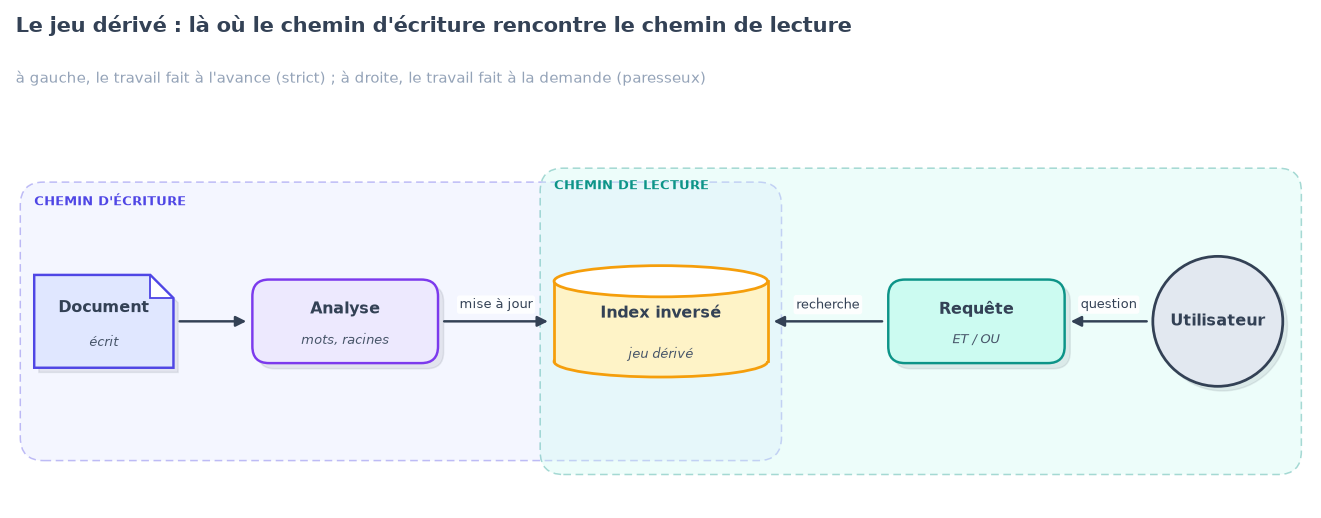

In [2]:
d = Diagram(14, 4.4, title="Le jeu dérivé : là où le chemin d'écriture rencontre le chemin de lecture",
            subtitle="à gauche, le travail fait à l'avance (strict) ; à droite, le travail fait à la demande (paresseux)")
d.box("doc", 1.0, 2.0, "Document", sub="écrit", color=INDIGO, kind="doc", w=1.5, h=1.0)
d.box("tok", 3.6, 2.0, "Analyse", sub="mots, racines", color=VIOLET, w=2.0)
d.box("idx", 7.0, 2.0, "Index inversé", sub="jeu dérivé", color=AMBER, kind="db", w=2.3, h=1.2)
d.box("q", 10.4, 2.0, "Requête", sub="ET / OU", color=TEAL, w=1.9)
d.box("u", 13.0, 2.0, "Utilisateur", kind="user", color=SLATE, w=1.4)
d.arrow("doc", "tok"); d.arrow("tok", "idx", "mise à jour")
d.arrow("q", "idx", "recherche"); d.arrow("u", "q", "question")
d.group(0.1, 0.5, 8.3, 3.5, "chemin d'écriture", color=INDIGO)
d.group(5.7, 0.35, 13.9, 3.65, "chemin de lecture", color=TEAL)
d.show()

> **À retenir.** Chemin d'écriture = travail précalculé dès l'arrivée des données ;
> chemin de lecture = travail fait à la demande. Tout jeu dérivé est un **compromis**
> entre ce qu'on fait à l'écriture et ce qu'on fait à la lecture.

## 2. Vues matérialisées et caches : déplacer la frontière (section *Materialized views and caching*)

Un index plein texte illustre bien le compromis. À l'écriture, il faut mettre à jour
l'entrée de chaque terme du document ; à la lecture, il faut chercher chaque mot de la
requête et combiner les listes (ET, OU). Il y a d'autres placements possibles de la
frontière :

- **pas d'index** : on parcourt tous les documents à chaque requête (comme `grep`) ;
  aucune écriture supplémentaire, une lecture très chère ;
- **tout précalculer** : stocker la réponse de **toutes** les requêtes possibles ;
  lecture triviale, mais le nombre de requêtes possibles est infini (au moins
  exponentiel dans le nombre de termes) : impossible ;
- **un cache des requêtes fréquentes** : on précalcule les réponses d'un ensemble fixe de
  requêtes populaires (une vue matérialisée, à mettre à jour quand un nouveau document
  correspond), les autres passent par l'index.

Mesurons ces stratégies sur un corpus synthétique (`dfl.make_corpus`, vocabulaire en loi
de Zipf) avec des requêtes de deux termes dont la popularité suit elle aussi une loi de
Zipf. On compte les opérations élémentaires : entrées de listes écrites ou lues, mots
parcourus, vérifications d'un document contre une requête en cache.

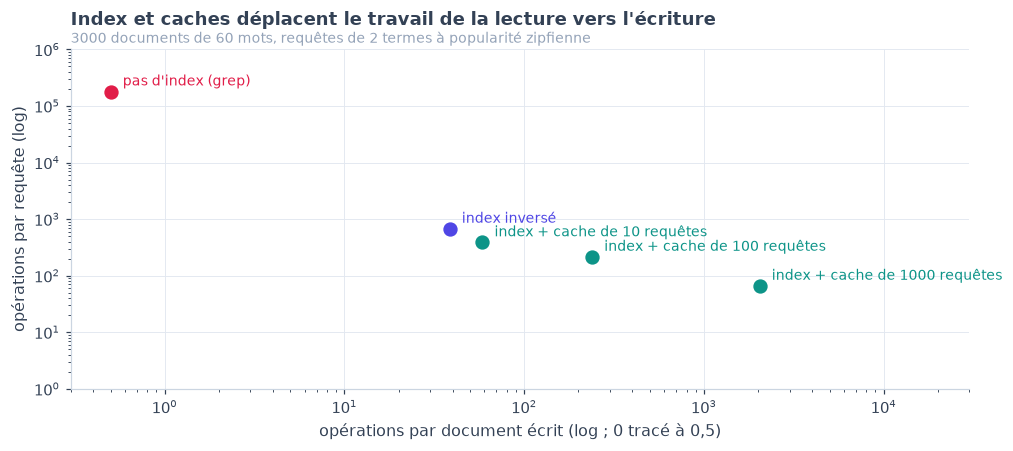

taux de succès du cache : K=10 42%, K=100 68%, K=1000 90%
requêtes possibles de 2 termes : 1 999 000 ; de 3 termes : 1 331 334 000


,stratégie,travail par écriture,travail par lecture
0,pas d'index (grep),0.000,180000.000
1,index inversé,38.474,673.337
2,index + cache de 10 requêtes,58.474,387.796
3,index + cache de 100 requêtes,238.474,215.005
4,index + cache de 1000 requêtes,2038.474,66.049


In [3]:
V, D, L = 2000, 3000, 60
corpus = dfl.make_corpus(D, vocab=V, doc_len=L, seed=1)
rng = np.random.default_rng(2)
distinct = [tuple(sorted(rng.choice(200, 2, replace=False))) for _ in range(5000)]   # requêtes de 2 termes fréquents
qs = dfl.zipf_queries(20_000, len(distinct), a=1.1, seed=3)

idx = dfl.InvertedIndex()
for i, doc in enumerate(corpus):
    idx.add(i, doc)
w_index = idx.write_ops / D                                   # opérations par document écrit
sample = qs[:400]
r_grep = np.mean([dfl.grep_search(corpus, distinct[q])[1] for q in sample[:40]])
idx.read_ops = 0
for q in sample:
    idx.search_and(distinct[q])
r_index = idx.read_ops / len(sample)
counts = np.bincount(qs, minlength=len(distinct))
order = np.argsort(-counts)

def cache_costs(K):
    hit = counts[order[:K]].sum() / counts.sum()
    w = w_index + K * 2                     # chaque document écrit est confronté aux K requêtes (2 termes)
    r = hit * 1 + (1 - hit) * r_index       # une réponse en cache se lit en une opération
    return w, r, hit

rows = [("pas d'index (grep)", 0.0, r_grep), ("index inversé", w_index, r_index)]
for K in (10, 100, 1000):
    w, r, hit = cache_costs(K)
    rows.append((f"index + cache de {K} requêtes", w, r))
C = pd.DataFrame(rows, columns=["stratégie", "travail par écriture", "travail par lecture"])
fig, ax = plt.subplots(figsize=(9.5, 4.2))
cols = [ROSE, INDIGO, TEAL, TEAL, TEAL]
for (name, w, r), c in zip(rows, cols):
    ax.scatter(max(w, 0.5), r, s=70, color=c, zorder=3)
    ax.annotate(name, (max(w, 0.5), r), (8, 4), textcoords="offset points", fontsize=9, color=c)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(0.3, 3e4); ax.set_ylim(1, 1e6)
ax.set_xlabel("opérations par document écrit (log ; 0 tracé à 0,5)"); ax.set_ylabel("opérations par requête (log)")
ax.set_title("Index et caches déplacent le travail de la lecture vers l'écriture")
subtitle(ax, f"{D} documents de {L} mots, requêtes de 2 termes à popularité zipfienne")
plt.tight_layout(); plt.show()
print(f"taux de succès du cache : K=10 {cache_costs(10)[2]:.0%}, K=100 {cache_costs(100)[2]:.0%}, K=1000 {cache_costs(1000)[2]:.0%}")
print(f"requêtes possibles de 2 termes : {V * (V - 1) // 2:,} ; de 3 termes : {math.comb(V, 3):,}".replace(",", " "))
C

Sans index, chaque requête parcourt les 180 000 mots du corpus ; l'index divise ce coût
par plus de deux cents, contre une quarantaine d'écritures par document (une par terme
distinct). Le cache des requêtes fréquentes pousse plus loin : avec 100 requêtes en
cache, plus des deux tiers des lectures coûtent une seule opération, mais **chaque** document écrit doit être confronté aux 100
requêtes. Quant au précalcul exhaustif, il faudrait tenir à jour 2 millions de réponses
pour les seules requêtes de deux termes, et plus d'un milliard pour trois termes.

Où placer la frontière dépend du **rapport lectures/écritures**. Le coût total par unité
de temps vaut $\text{écritures} \times w(K) + \text{lectures} \times r(K)$ : cherchons la
taille de cache optimale pour plusieurs rapports.

  1 lectures/écriture : K optimal = 37, coût = 56% du coût sans cache
 10 lectures/écriture : K optimal = 310, coût = 31% du coût sans cache
100 lectures/écriture : K optimal = 2602, coût = 8% du coût sans cache


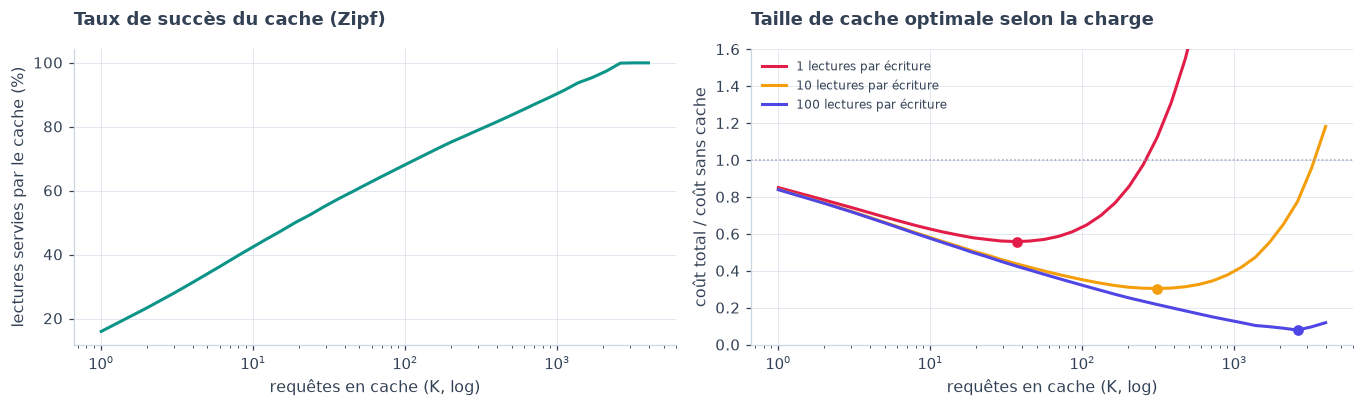

In [4]:
Ks = np.unique(np.logspace(0, 3.6, 40).astype(int))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 3.8))
ax1.plot(Ks, [cache_costs(K)[2] * 100 for K in Ks], color=TEAL)
ax1.set_xscale("log"); ax1.set_xlabel("requêtes en cache (K, log)"); ax1.set_ylabel("lectures servies par le cache (%)")
ax1.set_title("Taux de succès du cache (Zipf)")
for ratio, c in [(1, ROSE), (10, AMBER), (100, INDIGO)]:
    tot = np.array([cache_costs(K)[0] + ratio * cache_costs(K)[1] for K in Ks])
    base = w_index + ratio * r_index
    ax2.plot(Ks, tot / base, color=c, label=f"{ratio} lectures par écriture")
    k = Ks[np.argmin(tot)]
    ax2.scatter([k], [tot.min() / base], color=c, zorder=3)
    print(f"{ratio:>3} lectures/écriture : K optimal = {k}, coût = {tot.min() / base:.0%} du coût sans cache")
ax2.axhline(1, color=GRAY, ls=":", lw=1)
ax2.set_ylim(0, 1.6)
ax2.set_xscale("log"); ax2.set_xlabel("requêtes en cache (K, log)"); ax2.set_ylabel("coût total / coût sans cache")
ax2.set_title("Taille de cache optimale selon la charge"); ax2.legend(fontsize=8)
plt.tight_layout(); plt.show()

Le taux de succès croît comme le logarithme de la taille du cache (loi de Zipf :
quelques requêtes concentrent le trafic). Même avec une seule lecture par écriture, un
petit cache paie, car une lecture par l'index coûte bien plus cher qu'une écriture ;
mais l'optimum reste petit (quelques dizaines de requêtes) et le coût explose au-delà,
chaque document écrit devant être confronté à toutes les requêtes en cache. Plus les
lectures dominent, plus le cache optimal grandit (quelques centaines de requêtes pour
10 lectures par écriture, quelques milliers pour 100) et plus le gain est grand. Le rôle des
caches, index et vues matérialisées est donc simple : ils **déplacent la frontière**
entre chemin de lecture et chemin d'écriture, en faisant plus de travail à l'écriture
pour en économiser à la lecture.

C'était déjà le sujet de l'étude de cas des timelines du chapitre 1 :
matérialiser la timeline (fan-out à l'écriture) ou la calculer à la lecture, avec une
frontière placée différemment pour les célébrités. Le livre s'amuse d'avoir, cinq cents
pages plus tard, bouclé la boucle.

> **À retenir.** Index, caches et vues matérialisées sont des façons de placer la
> frontière entre écriture et lecture. Le bon placement dépend du rapport lectures /
> écritures et de la concentration des requêtes ; le précalcul total est impossible, le
> précalcul des requêtes fréquentes est souvent rentable.

## 3. Des clients avec état, capables de travailler hors ligne (section *Stateful, offline-capable clients*)

Longtemps, le navigateur web a été un client **sans état** : hors connexion, on ne pouvait
guère que faire défiler une page déjà chargée. Les applications web en une page
(JavaScript) et les applications mobiles gardent désormais beaucoup d'**état local** : la
plupart des interactions se passent sans aller-retour avec le serveur.

Cette évolution a suscité un intérêt pour les applications **offline-first**, qui font
le maximum avec une base de données locale à l'appareil, sans connexion, et se
synchronisent avec les serveurs en arrière-plan quand le réseau est disponible
(chapitre 5 : une forme de réplication multi-leader où chaque appareil
est un leader). Sur mobile, où la connexion est souvent lente et instable, c'est un gros
avantage que l'interface n'attende pas le réseau.

Le livre propose de voir l'état de l'appareil comme un **cache de l'état du serveur** :
les pixels à l'écran sont une vue matérialisée des objets du modèle de l'application,
et ces objets sont une réplique locale d'un état situé dans un centre de données. Un
appareil qui se reconnecte n'a pas besoin de tout recharger : comme un consommateur d'un
courtier à base de journal (chapitre 11), il reprend **à son dernier offset**.
Simulons un appareil connecté par intermittence à un flux de 2 événements par minute.

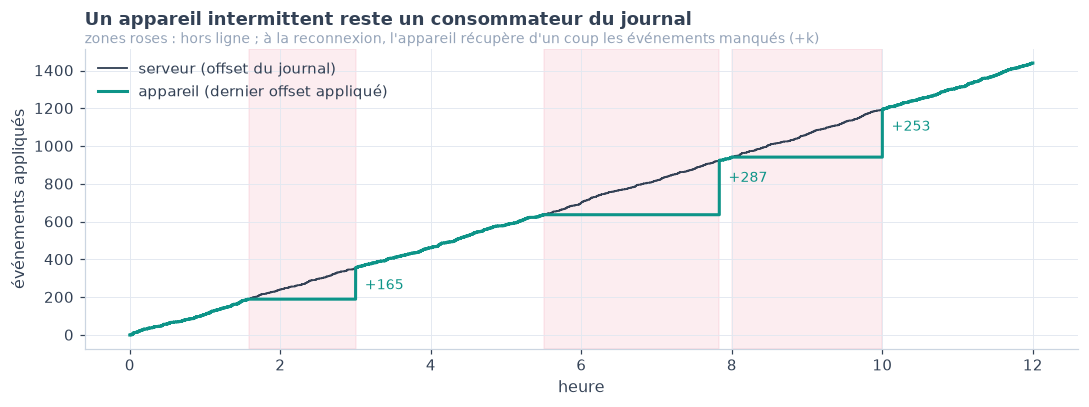

événements récupérés à chaque reconnexion : [165, 287, 253] ; état final identique : True


In [5]:
rng = np.random.default_rng(4)
horizon = 12 * 60                                          # minutes
t_events = np.sort(rng.uniform(0, horizon, int(2 * horizon)))
online = [(0, 95), (180, 330), (470, 480), (600, horizon)]   # périodes de connexion
server_v = np.arange(1, t_events.size + 1)
device_offset, dev_t, dev_v, fetched = 0, [0.0], [0], []
for a, b in online:
    # à la reconnexion : récupère d'un coup tout ce qui a été manqué depuis son offset
    missed = int(np.searchsorted(t_events, a, side="right"))
    if missed > device_offset:
        fetched.append((a, missed - device_offset))
        device_offset = missed
        dev_t.append(a); dev_v.append(device_offset)
    for t in t_events[(t_events > a) & (t_events <= b)]:   # puis reçoit les changements poussés
        device_offset += 1
        dev_t.append(t); dev_v.append(device_offset)
    dev_t.append(b); dev_v.append(device_offset)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.step(t_events / 60, server_v, where="post", color=SLATE, lw=1.2, label="serveur (offset du journal)")
ax.step(np.array(dev_t) / 60, dev_v, where="post", color=TEAL, lw=2, label="appareil (dernier offset appliqué)")
for a, b in [(95, 180), (330, 470), (480, 600)]:
    ax.axvspan(a / 60, b / 60, color=ROSE, alpha=0.08)
for a, k in fetched:
    ax.annotate(f"+{k}", (a / 60, np.interp(a, t_events, server_v)), (6, -14), textcoords="offset points",
                fontsize=9, color=TEAL)
ax.set_xlabel("heure"); ax.set_ylabel("événements appliqués")
ax.set_title("Un appareil intermittent reste un consommateur du journal")
subtitle(ax, "zones roses : hors ligne ; à la reconnexion, l'appareil récupère d'un coup les événements manqués (+k)")
ax.legend(loc="upper left"); plt.tight_layout(); plt.show()
print("événements récupérés à chaque reconnexion :", [k for _, k in fetched], "; état final identique :",
      device_offset == t_events.size)

Pendant les coupures, l'appareil fonctionne sur sa copie locale (périmée) ; à chaque
reconnexion, il récupère d'un bloc les événements manqués depuis son offset, puis
repasse en mode « poussé ». Aucun événement n'est perdu, et l'état final est identique à
celui du serveur. Le cas difficile, que ce modèle à lecture seule n'aborde pas, est
l'appareil qui **écrit** hors ligne : il faut alors résoudre des conflits (chapitre
5).

> **À retenir.** Un client avec état est une réplique, et ses pixels une vue
> matérialisée. Pour lui, se déconnecter revient à prendre du retard sur un journal, et
> se reconnecter à reprendre à son offset.